<a href="https://colab.research.google.com/github/Sharu-052897/deep-learning/blob/main/segmentation%20Attention%20UNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install -q --upgrade tensorflow-datasets importlib-resources

In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("TensorFlow Datasets version:", tfds.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0
TensorFlow Datasets version: 4.9.10


In [12]:
(train_raw, val_raw), info = tfds.load(
    'oxford_iiit_pet',
    split=['train[:80%]', 'train[80%:]'],
    with_info=True,
    as_supervised=False
)

print("Dataset downloaded successfully!")
print("Training images:", info.splits['train'].num_examples)
print("Training split: 80%")
print("Validation split: 20%")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.UW9R5Q_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.UW9R5Q_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Dataset downloaded successfully!
Training images: 3680
Training split: 80%
Validation split: 20%


In [13]:
IMG_SIZE = 128
BATCH_SIZE = 8

def preprocess(data):

    image = tf.image.resize(
        data['image'],
        (IMG_SIZE, IMG_SIZE)
    )

    mask = tf.image.resize(
        data['segmentation_mask'],
        (IMG_SIZE, IMG_SIZE),
        method='nearest'
    )

    image = tf.cast(image, tf.float32) / 255.0

    mask = tf.cast(mask, tf.int32) - 1
    mask = tf.squeeze(mask, axis=-1)

    return image, mask


train_data = train_raw.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_data = val_raw.map(
    preprocess,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_data = train_data.shuffle(300).batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

val_data = val_data.batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

print("Dataset preprocessing completed!")

Dataset preprocessing completed!


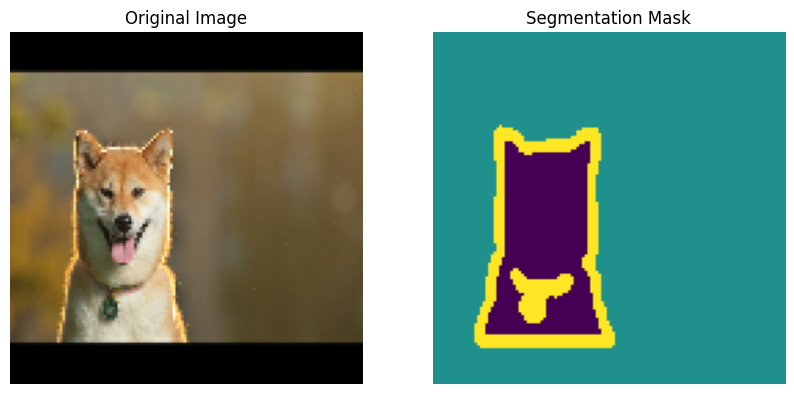

In [14]:
for images, masks in train_data.take(1):

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(images[0])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(masks[0], cmap='viridis')
    plt.title("Segmentation Mask")
    plt.axis("off")

    plt.show()

In [15]:
def unet_model():

    inputs = layers.Input((128, 128, 3))

    # Encoder
    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(inputs)
    c1 = layers.Conv2D(16, 3, activation='relu', padding='same')(c1)
    p1 = layers.MaxPooling2D()(c1)

    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(p1)
    c2 = layers.Conv2D(32, 3, activation='relu', padding='same')(c2)
    p2 = layers.MaxPooling2D()(c2)

    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(p2)
    c3 = layers.Conv2D(64, 3, activation='relu', padding='same')(c3)
    p3 = layers.MaxPooling2D()(c3)

    # Bottleneck
    b = layers.Conv2D(128, 3, activation='relu', padding='same')(p3)

    # Decoder
    u1 = layers.Conv2DTranspose(64, 2, strides=2, padding='same')(b)
    u1 = layers.Concatenate()([u1, c3])
    d1 = layers.Conv2D(64, 3, activation='relu', padding='same')(u1)

    u2 = layers.Conv2DTranspose(32, 2, strides=2, padding='same')(d1)
    u2 = layers.Concatenate()([u2, c2])
    d2 = layers.Conv2D(32, 3, activation='relu', padding='same')(u2)

    u3 = layers.Conv2DTranspose(16, 2, strides=2, padding='same')(d2)
    u3 = layers.Concatenate()([u3, c1])
    d3 = layers.Conv2D(16, 3, activation='relu', padding='same')(u3)

    outputs = layers.Conv2D(3, 1, activation='softmax')(d3)

    return Model(inputs, outputs)


unet = unet_model()

print("UNet model created successfully!")
print("Output shape:", unet.output_shape)

unet.summary()

UNet model created successfully!
Output shape: (None, 128, 128, 3)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 128, 128,  │        448 │ input_layer_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 128, 128,  │      2,320 │ conv2d_24[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ conv2d_25[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 64, 64,    │      4,640 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_26[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ conv2d_27[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_28[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ conv2d_29[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 32, 32,    │     32,832 │ conv2d_30[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 32, 32,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 128)              │            │ conv2d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 32, 32,    │     73,792 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_4  │ (None, 64, 64,    │      8,224 │ conv2d_31[0][0]   │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_27[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 64, 64,    │     18,464 │ concatenate_4[0]

 Total params: 285,987 (1.09 MB)

 Trainable params: 285,987 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
unet.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

unet_history = unet.fit(
    train_data,
    validation_data=val_data,
    epochs=3
)

Epoch 1/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 50s 52ms/step - accuracy: 0.6634 - loss: 0.8018 - val_accuracy: 0.7029 - val_loss: 0.7357
Epoch 2/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 46s 29ms/step - accuracy: 0.7101 - loss: 0.7189 - val_accuracy: 0.7287 - val_loss: 0.6697
Epoch 3/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 26s 41ms/step - accuracy: 0.7390 - loss: 0.6429 - val_accuracy: 0.7661 - val_loss: 0.6045


In [17]:
def attention_gate(skip, gate, filters):

    theta = layers.Conv2D(
        filters, 1, padding='same'
    )(skip)

    phi = layers.Conv2D(
        filters, 1, padding='same'
    )(gate)

    x = layers.Add()([theta, phi])

    x = layers.Activation('relu')(x)

    psi = layers.Conv2D(
        1, 1, activation='sigmoid'
    )(x)

    output = layers.Multiply()([skip, psi])

    return output


print("Attention Gate created successfully!")

Attention Gate created successfully!


In [18]:
def conv_block(x, filters):

    x = layers.Conv2D(
        filters, 3, padding='same', activation='relu'
    )(x)

    x = layers.Conv2D(
        filters, 3, padding='same', activation='relu'
    )(x)

    return x


def attention_unet():

    inputs = layers.Input((128, 128, 3))

    # Encoder
    c1 = conv_block(inputs, 16)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 32)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 64)
    p3 = layers.MaxPooling2D()(c3)

    # Bottleneck
    b = conv_block(p3, 128)

    # Decoder 1
    u1 = layers.Conv2DTranspose(
        64, 2, strides=2, padding='same'
    )(b)

    a1 = attention_gate(c3, u1, 64)
    u1 = layers.Concatenate()([u1, a1])
    d1 = conv_block(u1, 64)

    # Decoder 2
    u2 = layers.Conv2DTranspose(
        32, 2, strides=2, padding='same'
    )(d1)

    a2 = attention_gate(c2, u2, 32)
    u2 = layers.Concatenate()([u2, a2])
    d2 = conv_block(u2, 32)

    # Decoder 3
    u3 = layers.Conv2DTranspose(
        16, 2, strides=2, padding='same'
    )(d2)

    a3 = attention_gate(c1, u3, 16)
    u3 = layers.Concatenate()([u3, a3])
    d3 = conv_block(u3, 16)

    outputs = layers.Conv2D(
        3, 1, activation='softmax'
    )(d3)

    return Model(inputs, outputs)


attention_model = attention_unet()

print("Attention UNet created successfully!")
print("Output shape:", attention_model.output_shape)

attention_model.summary()

Attention UNet created successfully!
Output shape: (None, 128, 128, 3)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 128, 128,  │        448 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 128, 128,  │      2,320 │ conv2d_35[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ conv2d_36[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 64, 64,    │      4,640 │ max_pooling2d_6[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_37[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 32, 32,    │          0 │ conv2d_38[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 32, 32,    │     18,496 │ max_pooling2d_7[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_40 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_39[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 16, 16,    │          0 │ conv2d_40[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_41 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_8[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_41[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_6  │ (None, 32, 32,    │     32,832 │ conv2d_42[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │      4,160 │ conv2d_40[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 32, 32,    │      4,160 │ conv2d_transpose… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 32, 32,    │          0 │ conv2d_43[0][0],  │
│                     │ 64)               │            │ conv2d_44[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ add_3[0][0]     

 Total params: 493,158 (1.88 MB)

 Trainable params: 493,158 (1.88 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
attention_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

attention_history = attention_model.fit(
    train_data,
    validation_data=val_data,
    epochs=3
)

Epoch 1/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 42s 55ms/step - accuracy: 0.6600 - loss: 0.7989 - val_accuracy: 0.7172 - val_loss: 0.7021
Epoch 2/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.7281 - loss: 0.6695 - val_accuracy: 0.7535 - val_loss: 0.6100
Epoch 3/3
368/368 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - accuracy: 0.7668 - loss: 0.5841 - val_accuracy: 0.7925 - val_loss: 0.5249


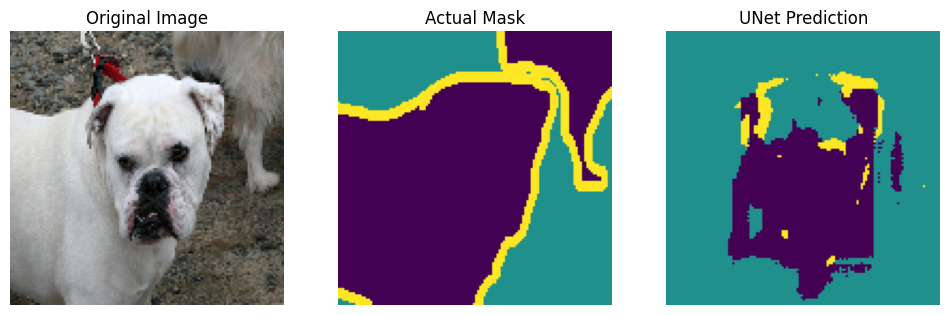

In [20]:
for images, masks in val_data.take(1):

    prediction = unet.predict(images, verbose=0)

    predicted_mask = np.argmax(prediction[0], axis=-1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(images[0])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(masks[0], cmap='viridis')
    plt.title("Actual Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(predicted_mask, cmap='viridis')
    plt.title("UNet Prediction")
    plt.axis("off")

    plt.show()

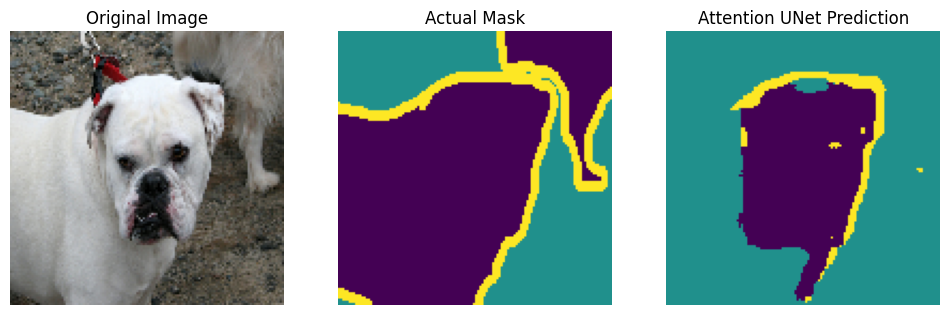

In [21]:
for images, masks in val_data.take(1):

    prediction = attention_model.predict(images, verbose=0)

    predicted_mask = np.argmax(prediction[0], axis=-1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(images[0])
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(masks[0], cmap='viridis')
    plt.title("Actual Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(predicted_mask, cmap='viridis')
    plt.title("Attention UNet Prediction")
    plt.axis("off")

    plt.show()

In [22]:
def calculate_iou(model, dataset):

    confusion = np.zeros((3, 3), dtype=np.int64)

    for images, masks in dataset:

        prediction = model.predict(images, verbose=0)

        predicted = np.argmax(prediction, axis=-1)

        actual = masks.numpy().flatten()
        predicted = predicted.flatten()

        batch_matrix = tf.math.confusion_matrix(
            actual,
            predicted,
            num_classes=3
        ).numpy()

        confusion += batch_matrix

    intersection = np.diag(confusion)

    union = (
        np.sum(confusion, axis=0) +
        np.sum(confusion, axis=1) -
        intersection
    )

    iou = intersection / np.maximum(union, 1)

    mean_iou = np.mean(iou)

    return iou, mean_iou


print("Calculating UNet IoU...")

unet_iou, unet_mean_iou = calculate_iou(
    unet, val_data
)

print("UNet IoU scores:", unet_iou)
print("UNet Mean IoU:", round(unet_mean_iou, 4))

print("\nCalculating Attention UNet IoU...")

attention_iou, attention_mean_iou = calculate_iou(
    attention_model, val_data
)

print("Attention UNet IoU scores:", attention_iou)
print("Attention UNet Mean IoU:", round(attention_mean_iou, 4))

Calculating UNet IoU...
UNet IoU scores: [0.55646037 0.73758838 0.18879069]
UNet Mean IoU: 0.4943

Calculating Attention UNet IoU...
Attention UNet IoU scores: [0.59099611 0.7703014  0.23278708]
Attention UNet Mean IoU: 0.5314


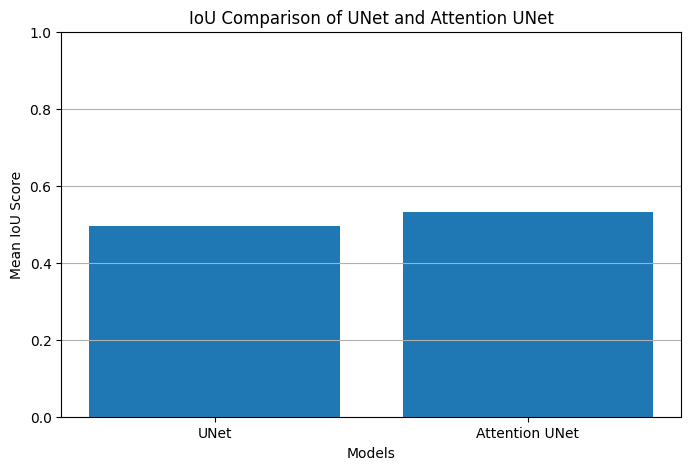

UNet Mean IoU: 0.4943
Attention UNet Mean IoU: 0.5314


In [23]:
models_name = ['UNet', 'Attention UNet']

iou_scores = [
    unet_mean_iou,
    attention_mean_iou
]

plt.figure(figsize=(8, 5))

plt.bar(models_name, iou_scores)

plt.title("IoU Comparison of UNet and Attention UNet")
plt.xlabel("Models")
plt.ylabel("Mean IoU Score")

plt.ylim(0, 1)
plt.grid(axis='y')

plt.show()

print("UNet Mean IoU:", round(unet_mean_iou, 4))
print("Attention UNet Mean IoU:", round(attention_mean_iou, 4))

In [24]:
if attention_mean_iou > unet_mean_iou:

    print("Attention UNet performed better!")

elif unet_mean_iou > attention_mean_iou:

    print("UNet performed better!")

else:

    print("Both models have equal performance!")

Attention UNet performed better!
